<a href="https://colab.research.google.com/github/Kishore-Krish19/ML/blob/main/Sentiment_Analysis_Comparision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Sentiment Analysis on dataset by building and comparing NN, RNN, LST and GRU**

In [2]:
!pip -q install datasets pandas matplotlib seaborn scikit-learn optuna

Loading the Dataset

In [3]:
from datasets import load_dataset
import pandas as pd
import torch

dataset = load_dataset(
    "Sp1786/multiclass-sentiment-analysis-dataset"
)

print(dataset)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})
PyTorch version: 2.14.1+cpu
GPU available: False


EDA

In [4]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nFirst five training records:")
print(train_df.head())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nSentiment distribution:")
print(train_df["sentiment"].value_counts())

print("\nDuplicate training texts:")
print(train_df["text"].duplicated().sum())

Training samples: 31232
Validation samples: 5205
Testing samples: 5206

First five training records:
      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative

Missing values:
id           0
text         0
label        0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64

Duplicate training texts:
0


Data Distribution analysis

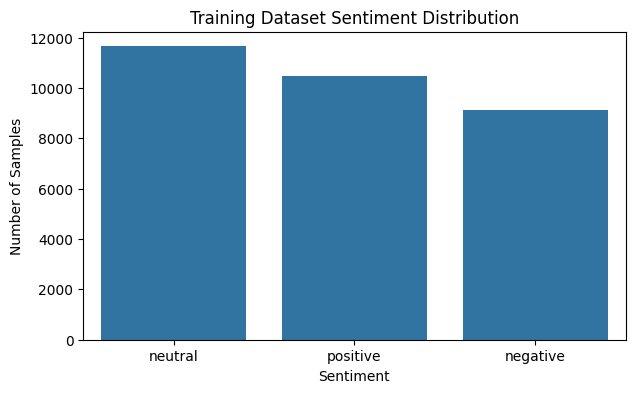

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count samples for each sentiment
sentiment_counts = train_df["sentiment"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 4))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Training Dataset Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")

plt.show()

Text Processing:
1. Tokenization

In [6]:
# Select the first sentence from our dataset
sentence = train_df["text"].iloc[0]

print("Original sentence:")
print(sentence)

# Convert sentence into tokens
tokens = sentence.split()

print("\nTokens:")
print(tokens)

print("\nNumber of tokens:", len(tokens))

Original sentence:
Cooking microwave pizzas, yummy

Tokens:
['Cooking', 'microwave', 'pizzas,', 'yummy']

Number of tokens: 4
